# AI-Assisted Testing of Trading Strategies
### An educational implementation inspired by Sträßer & Stolicna (2025)


## 1. Objective and connection to the paper

Sträßer and Stolicna (2025) propose a conceptual approach to testing
high-frequency trading (HFT) strategies while considering applicable
regulatory requirements. They discuss potential applications of artificial
intelligence, including scenario generation, stress testing and anomaly
detection

The paper does not provide a dataset, an implemented algorithm or
quantitative experimental results. This notebook therefore presents our
own educational implementation of selected ideas from the paper

### Research questions

1. How does a simple mean-reversion strategy behave under normal and
   stressed market conditions?
2. How do position limits and a loss-triggered trading stop affect its
   behaviour and financial outcomes?
3. How does an Isolation Forest model compare with a simple threshold
   baseline when detecting anomalies in simulated trading activity?

### Experimental structure

**Experiment A - Strategy and risk controls**

We simulate market prices and compare the same trading strategy with
and without risk controls. Both versions use identical market paths
and execution assumptions, including spread and transaction fees

**Experiment B - Anomaly detection**

We generate a separate dataset of simulated trading activity windows.
We train an anomaly detector on normal observations, calibrate alert
thresholds on a separate normal sample and evaluate detection on held-out
data containing labelled synthetic anomalies

The detector is evaluated as a monitoring tool. It does not control the
strategy in Experiment A

### Scope and interpretation

- All data are synthetic and generated using fixed random seeds
- This is a simplified trading simulation, not a full HFT execution system
- Risk limits are illustrative internal controls, not implementations of
  specific legal requirements
- Synthetic anomaly labels describe injected events; they do not establish
  market manipulation or regulatory violations
- Results describe behaviour under our simulation assumptions and do not
  establish profitability in real markets

### Reference

Sträßer, J., & Stolicna, Z. (2025)
*Combination of test methods and scenarios using Artificial Intelligence to cover High-Frequency Trading (HFT) strategies in conjunction with
country-specific regulatory requirements.*
Procedia Computer Science, 257, 1014–1020

https://doi.org/10.1016/j.procs.2025.03.131

## 2. Setup and experiment parameters

This notebook uses NumPy and pandas for data processing, Matplotlib for
visualisation and scikit-learn for anomaly detection

All random samples are generated using explicit seeds. Package versions
are printed below to document the execution environment

### Trading experiment

We simulate one asset priced in arbitrary currency units. One observation
represents one simulation step; no specific real-world time frequency
is assumed

The strategy is long-only: it can buy the asset, hold it or close its
position. It cannot sell short

We compare two configurations:

- **Without controls:** no position limit or loss-triggered stop
- **With controls:** a maximum position and a loss-triggered stop

Both configurations use the same initial cash, trading signals,
transaction costs and available-cash constraint. Borrowing is not allowed

The loss limit is measured relative to initial equity. When triggered,
the strategy attempts to liquidate its position and stops trading for the
rest of the simulation. The realised loss may exceed the threshold
because of price changes and liquidation costs

All parameter values below are illustrative choices for this experiment,
not values estimated or reported in the paper

In [29]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_score, recall_score, f1_score)

SEED = 42

MARKET = {
    "n_steps": 2_000,
    "initial_price": 100.0,
    "mean_price": 100.0,
    "mean_reversion_strength": 0.02,
    "noise_std": 0.20,
}

TRADING = {
    "initial_cash": 10_000.0,
    "lookback": 50,
    "entry_z": -1.5,
    "exit_z": 0.0,
    "order_size": 10,
    "spread_bps": 2.0,
    "fee_bps": 1.0,
}

RISK = {
    "max_position": 50,
    "loss_limit": 150.0,
}

SIMULATION_SEEDS = list(range(SEED, SEED + 20))

DETECTION = {
    "n_train": 3_000,
    "n_calibration": 2_000,
    "n_test": 2_000,
    "test_anomaly_fraction": 0.06,
    "target_false_positive_rate": 0.01,
    "n_estimators": 200,
}

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

versions = pd.Series({
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "Matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
}, name="Version")

display(versions.to_frame())
print("Setup complete")

,Version
Python,3.13.16
NumPy,2.1.3
pandas,2.2.3
Matplotlib,3.10.0
scikit-learn,1.6.1


Setup complete


## 3. Synthetic market scenarios

We simulate the asset's mid-price using a discrete mean-reverting process:

$$
P_t = P_{t-1} + \kappa(\mu_t - P_{t-1}) + \sigma_t \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal{N}(0,1)
$$

Here:

- $P_t$ is the mid-price at step $t$
- $\mu_t$ is the reference level towards which the price tends to move
- $\kappa$ controls the strength of mean reversion
- $\sigma_t$ controls the size of random price changes

This is an illustrative simulation model chosen for our experiment.
It is not specified or estimated in the paper

### Scenarios

| Scenario | Construction | Testing purpose |
|---|---|---|
| Normal | Constant reference level and noise scale | Establish baseline behaviour |
| High volatility | Noise scale increases fourfold between 40% and 75% of the simulation | Test sensitivity to larger price changes |
| Persistent decline | Reference level decreases by 0.02 currency units per step from 40% of the simulation onward | Test repeated buying in a falling market |

These stress settings are illustrative and are not calibrated to real
market data

For a given seed, all scenarios share the same sequence of random shocks.
Later, the controlled and uncontrolled strategies will also receive
identical prices within each scenario

The reference level and stress indicators are simulator metadata.
The trading strategy will use observed prices only

In [30]:
SCENARIOS = {
    "normal": "Normal",
    "high_volatility": "High volatility",
    "persistent_decline": "Persistent decline",
}


def simulate_market(scenario, seed=SEED, market=None):
    if scenario not in SCENARIOS:
        raise ValueError(f"Unknown scenario: {scenario}")

    parameters = MARKET if market is None else market
    n_steps = parameters["n_steps"]

    if n_steps < 10:
        raise ValueError("The simulation requires at least 10 steps")

    rng = np.random.default_rng(seed)
    shocks = rng.standard_normal(n_steps - 1)

    reference = np.full(n_steps, parameters["mean_price"], dtype=float)
    noise_scale = np.full(n_steps, parameters["noise_std"], dtype=float)
    stress_active = np.zeros(n_steps, dtype=bool)

    stress_start = int(0.40 * n_steps)
    volatility_end = int(0.75 * n_steps)

    if scenario == "high_volatility":
        noise_scale[stress_start:volatility_end] *= 4.0
        stress_active[stress_start:volatility_end] = True

    elif scenario == "persistent_decline":
        steps_into_decline = np.arange(1, n_steps - stress_start + 1)
        reference[stress_start:] -= 0.02 * steps_into_decline
        stress_active[stress_start:] = True

    prices = np.empty(n_steps, dtype=float)
    prices[0] = parameters["initial_price"]

    for t in range(1, n_steps):
        reversion = (parameters["mean_reversion_strength"] * (reference[t] - prices[t - 1]))
        random_change = noise_scale[t] * shocks[t - 1]
        prices[t] = prices[t - 1] + reversion + random_change

    if not np.isfinite(prices).all() or np.any(prices <= 0):
        raise ValueError(
            "The simulation produced invalid prices. "
            "Review the noise scale, decline rate or simulation length"
        )

    return pd.DataFrame({
        "step": np.arange(n_steps),
        "mid_price": prices,
        "reference_price": reference,
        "noise_scale": noise_scale,
        "stress_active": stress_active,
    })


markets = {scenario: simulate_market(scenario, seed=SEED) for scenario in SCENARIOS}

display(markets["normal"].head())

,step,mid_price,reference_price,noise_scale,stress_active
0,0,100.000,100.000,0.200,False
1,1,100.061,100.000,0.200,False
2,2,99.852,100.000,0.200,False
3,3,100.005,100.000,0.200,False
4,4,100.193,100.000,0.200,False


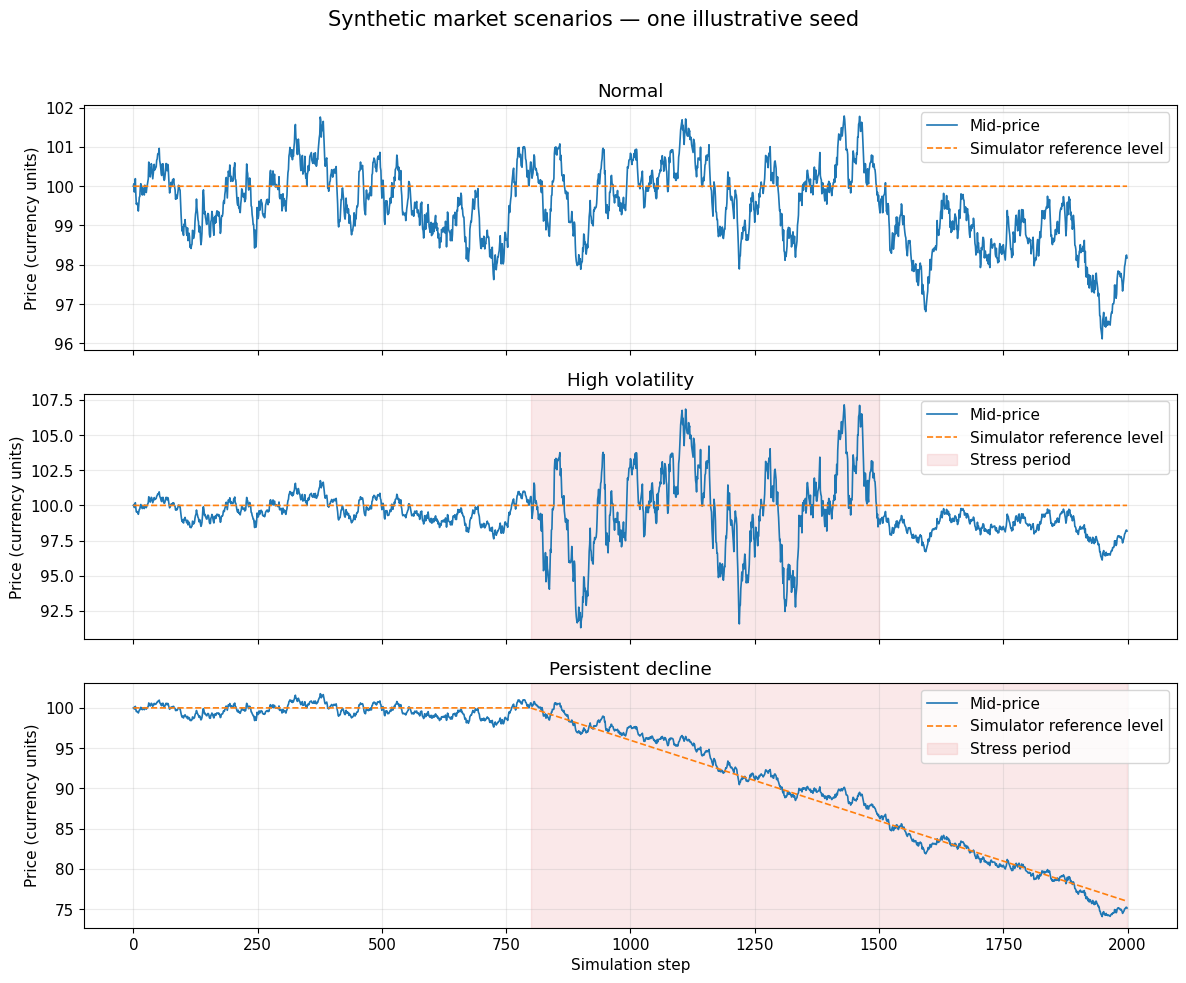

In [31]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 10),
    sharex=True,
)

for ax, (scenario, data) in zip(axes, markets.items()):
    ax.plot(
        data["step"],
        data["mid_price"],
        label="Mid-price",
        linewidth=1.2,
        color="tab:blue",
    )
    ax.plot(
        data["step"],
        data["reference_price"],
        label="Simulator reference level",
        linestyle="--",
        linewidth=1.2,
        color="tab:orange",
    )

    stressed_steps = data.loc[data["stress_active"], "step"]

    if not stressed_steps.empty:
        ax.axvspan(
            stressed_steps.iloc[0] - 0.5,
            stressed_steps.iloc[-1] + 0.5,
            color="tab:red",
            alpha=0.10,
            label="Stress period",
        )

    ax.set_title(SCENARIOS[scenario])
    ax.set_ylabel("Price (currency units)")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Simulation step")
fig.suptitle("Synthetic market scenarios — one illustrative seed", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.96))

fig.savefig(
    OUTPUT_DIR / "01_market_scenarios.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Interpretation

The normal scenario fluctuates around a constant reference level.
The high-volatility scenario increases the magnitude of random price
changes during a predefined interval. In the persistent-decline scenario,
the reference level continues to fall, challenging the assumption that
a price decrease will be followed by a recovery

These plots illustrate the scenario construction. They do not yet show
strategy performance. A separate set of repeated simulations will assess
how sensitive the results are to the random seed

## 4. Mean-reversion trading signals

The strategy compares the current mid-price with the recent price history.

For a lookback window of $L$ observations, we calculate the mean and
sample standard deviation using prices from $t-L$ through $t-1$:

$$
m_t = \frac{1}{L}\sum_{j=1}^{L} P_{t-j},
$$

$$
s_t =
\sqrt{
\frac{1}{L-1}
\sum_{j=1}^{L}(P_{t-j}-m_t)^2
}
$$

The trading signal is based on the rolling z-score:

$$
z_t = \frac{P_t-m_t}{s_t}.
$$

A negative z-score means that the current price is below its recent mean.
This is a descriptive signal, not a calibrated probability of recovery

### Trading rules

- If $z_t \leq -1.5$, request a purchase of 10 asset units
- If $z_t \geq 0$, request closure of the entire existing position
- Otherwise, hold the current position

A buy signal may occur on consecutive steps, so the strategy may accumulate
a position. Orders remain subject to available cash and, in the controlled
configuration, the risk limits introduced later

### Information and execution timing

At the end of step $t$, the strategy observes $P_t$ and generates a signal.
The order is executed at step $t+1$, using the next mid-price adjusted for
spread and fees

The first 50 observations provide the initial history. No signal is
generated when the historical standard deviation is zero or unavailable

Only mid-prices enter the signal calculation. Simulator reference levels,
stress indicators and future prices are not used

In [32]:
def calculate_signals(market_data, trading=None):
    parameters = TRADING if trading is None else trading
    lookback = parameters["lookback"]

    if lookback < 2:
        raise ValueError("The lookback window must contain at least 2 prices")

    prices = market_data["mid_price"].astype(float)

    historical_prices = prices.shift(1)

    rolling_mean = historical_prices.rolling(window=lookback, min_periods=lookback).mean()

    rolling_std = historical_prices.rolling(window=lookback, min_periods=lookback,).std(ddof=1)

    valid_std = rolling_std.where(rolling_std > 0)
    z_score = (prices - rolling_mean) / valid_std

    signals = pd.DataFrame({
        "step": market_data["step"],
        "mid_price": prices,
        "rolling_mean": rolling_mean,
        "rolling_std": rolling_std,
        "z_score": z_score,
    })

    signals["buy_signal"] = z_score.le(parameters["entry_z"])
    signals["exit_signal"] = z_score.ge(parameters["exit_z"])

    return signals


signals_by_scenario = {
    scenario: calculate_signals(data)
    for scenario, data in markets.items()
}

lookback = TRADING["lookback"]
display(signals_by_scenario["normal"].iloc[lookback - 2:lookback + 6])

,step,mid_price,rolling_mean,rolling_std,z_score,buy_signal,exit_signal
48,48,100.695,NaN,NaN,NaN,False,False
49,49,100.817,NaN,NaN,NaN,False,False
50,50,100.814,100.098,0.357,2.005,False,True
51,51,100.856,100.114,0.371,1.999,False,True
52,52,100.965,100.130,0.386,2.166,False,True
53,53,100.654,100.152,0.401,1.252,False,True
54,54,100.577,100.165,0.407,1.014,False,True
55,55,100.472,100.173,0.411,0.728,False,True


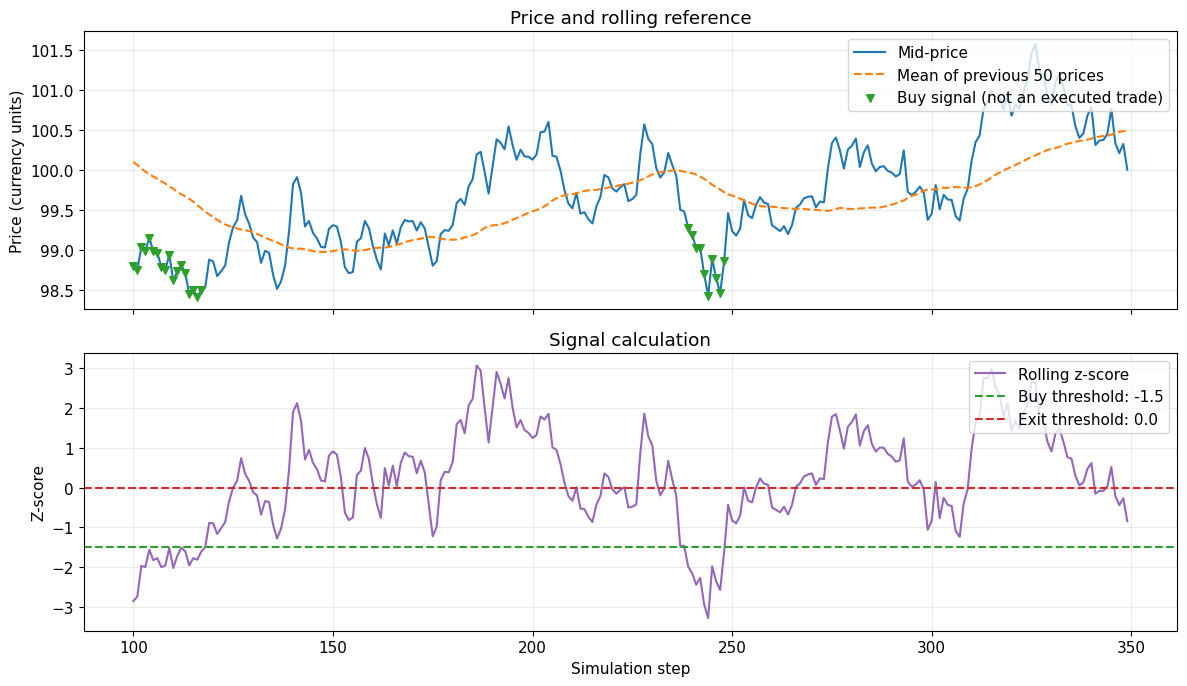

In [33]:
example = signals_by_scenario["normal"]

window = example.iloc[100:350]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 7),
    sharex=True,
)

axes[0].plot(
    window["step"],
    window["mid_price"],
    label="Mid-price",
    color="tab:blue",
)
axes[0].plot(
    window["step"],
    window["rolling_mean"],
    label="Mean of previous 50 prices",
    color="tab:orange",
    linestyle="--",
)

buy_points = window.loc[window["buy_signal"]]

axes[0].scatter(
    buy_points["step"],
    buy_points["mid_price"],
    marker="v",
    color="tab:green",
    s=30,
    label="Buy signal (not an executed trade)",
    zorder=3,
)

axes[0].set_title("Price and rolling reference")
axes[0].set_ylabel("Price (currency units)")
axes[0].legend(loc="upper right")

axes[1].plot(
    window["step"],
    window["z_score"],
    color="tab:purple",
    label="Rolling z-score",
)
axes[1].axhline(
    TRADING["entry_z"],
    color="tab:green",
    linestyle="--",
    label=f"Buy threshold: {TRADING['entry_z']}",
)
axes[1].axhline(
    TRADING["exit_z"],
    color="tab:red",
    linestyle="--",
    label=f"Exit threshold: {TRADING['exit_z']}",
)

axes[1].set_title("Signal calculation")
axes[1].set_xlabel("Simulation step")
axes[1].set_ylabel("Z-score")
axes[1].legend(loc="upper right")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "02_trading_signals.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Interpretation

Buy signals appear when the price falls sufficiently below its recent
mean. An exit signal appears when the price reaches or exceeds that mean

A signal is an instruction to consider an order, not evidence that a trade
was executed. Execution depends on the next price, available cash and
the enabled controls

The strategy assumes that deviations may reverse. During a persistent
decline, repeated buy signals can increase exposure while losses accumulate

## 5. Trade execution and risk controls

### Execution assumptions

A signal observed at step $t$ can be executed at step $t+1$

Purchases execute above the mid-price and sales below it:

$$
P_t^{buy} = P_t(1+h), \qquad
P_t^{sell} = P_t(1-h),
$$

where $h$ is half the full bid–ask spread, expressed as a fraction.
An additional fee is charged on the executed trade value

Orders are filled completely or rejected. Purchases require sufficient
cash to cover both the trade value and its fee. Borrowing and short
selling are not allowed

We assume sufficient liquidity for immediate execution at these prices.
Market impact, partial fills and additional execution slippage are omitted

### Portfolio accounting

After execution, equity is marked at the current mid-price:

$$
E_t = C_t + Q_t P_t,
$$

where $C_t$ is cash and $Q_t$ is the number of asset units held

Profit and loss relative to initial equity are:

$$
PnL_t = E_t - E_0
$$

### Controlled configuration

1. **Position limit:** reject a purchase if the resulting position would
   exceed 50 units
2. **Loss-triggered stop:** if end-of-step P&L reaches or falls below
   −150 currency units, cancel further strategy orders and liquidate
   the position at the next step. Trading then remains disabled

The stop has a one-step execution delay. It does not guarantee that the
final loss will remain within 150 currency units

### End of the experiment

At the final step, any remaining position is liquidated, including
spread and fees. New purchases are not allowed at that step.
This scheduled liquidation is applied to both configurations

In [34]:
def execute_trade(mid_price, signed_quantity, trading):
    half_spread = trading["spread_bps"] / 20_000
    fee_rate = trading["fee_bps"] / 10_000

    direction = np.sign(signed_quantity)
    fill_price = mid_price * (1 + direction * half_spread)

    trade_value = abs(signed_quantity) * fill_price
    fee = trade_value * fee_rate

    cash_change = -signed_quantity * fill_price - fee

    spread_cost = (abs(signed_quantity) * abs(fill_price - mid_price))

    return cash_change, fill_price, fee, spread_cost


def run_backtest(market_data, with_controls, trading=None, risk=None):
    trading = TRADING if trading is None else trading
    risk = RISK if risk is None else risk

    signals = calculate_signals(market_data, trading).reset_index(drop=True)

    if len(signals) < 2:
        raise ValueError("At least two price observations are required")

    prices = signals["mid_price"].to_numpy()
    if not np.isfinite(prices).all() or np.any(prices <= 0):
        raise ValueError("Prices must be finite and strictly positive")

    cash = float(trading["initial_cash"])
    initial_equity = cash
    position = 0
    halted = False

    cumulative_fees = 0.0
    cumulative_spread_cost = 0.0
    records = []

    for t in range(len(signals)):
        mid_price = float(prices[t])

        quantity = 0
        event = "hold"

        if halted:
            if position > 0:
                quantity = -position
                event = "loss_stop"
            else:
                event = "halted"

        elif t == len(signals) - 1:
            if position > 0:
                quantity = -position
                event = "end_liquidation"
            else:
                event = "end"

        elif t > 0:
            previous_signal = signals.iloc[t - 1]

            if previous_signal["exit_signal"] and position > 0:
                quantity = -position
                event = "strategy_exit"

            elif previous_signal["buy_signal"]:
                requested_quantity = trading["order_size"]

                exceeds_position_limit = (
                    with_controls
                    and position + requested_quantity > risk["max_position"]
                )

                if exceeds_position_limit:
                    event = "blocked_position_limit"

                else:
                    purchase_cash_change, _, _, _ = execute_trade(
                        mid_price,
                        requested_quantity,
                        trading,
                    )

                    if cash + purchase_cash_change < 0:
                        event = "blocked_cash"
                    else:
                        quantity = requested_quantity
                        event = "strategy_buy"

        fill_price = np.nan
        fee = 0.0
        spread_cost = 0.0

        if quantity != 0:
            cash_change, fill_price, fee, spread_cost = execute_trade(
                mid_price,
                quantity,
                trading,
            )

            cash += cash_change
            position += quantity
            cumulative_fees += fee
            cumulative_spread_cost += spread_cost

        equity = cash + position * mid_price
        pnl = equity - initial_equity

        stop_triggered = (with_controls and not halted and pnl <= -risk["loss_limit"])

        if stop_triggered:
            halted = True

        records.append({
            "step": signals.iloc[t]["step"],
            "mid_price": mid_price,
            "cash": cash,
            "position": position,
            "equity": equity,
            "pnl": pnl,
            "trade_quantity": quantity,
            "fill_price": fill_price,
            "fee": fee,
            "spread_cost": spread_cost,
            "cumulative_fees": cumulative_fees,
            "cumulative_spread_cost": cumulative_spread_cost,
            "event": event,
            "stop_triggered": stop_triggered,
            "halted": halted,
        })

    history = pd.DataFrame(records)

    trade_columns = [
        "step",
        "event",
        "trade_quantity",
        "mid_price",
        "fill_price",
        "fee",
        "spread_cost",
        "cash",
        "position",
    ]

    trades = history.loc[
        history["trade_quantity"].ne(0),
        trade_columns,
    ].reset_index(drop=True)

    return {
        "history": history,
        "trades": trades,
    }

In [35]:
backtests = {}

for scenario, market_data in markets.items():
    for with_controls in [False, True]:
        result = run_backtest(market_data, with_controls=with_controls,)

        backtests[(scenario, with_controls)] = result
        history = result["history"]

        assert (history["cash"] >= -1e-8).all(), "Negative cash balance"
        assert (history["position"] >= 0).all(), "Short position detected"
        assert history["position"].iloc[-1] == 0, "Position not liquidated"

        assert np.allclose(
            history["equity"],
            history["cash"]
            + history["position"] * history["mid_price"],
        ), "Portfolio accounting mismatch"

        if with_controls:
            assert (history["position"] <= RISK["max_position"]).all(), "Position limit exceeded"

        trigger_rows = np.flatnonzero(history["stop_triggered"].to_numpy())

        if len(trigger_rows) > 0:
            first_trigger = trigger_rows[0]

            assert not (
                history.iloc[first_trigger + 1:]["trade_quantity"] > 0
            ).any(), "Purchase executed after the stop"

print("All six illustrative backtests completed")
print("Accounting and portfolio checks passed")

print("\nFirst executed trades: normal scenario, with controls")
display(backtests[("normal", True)]["trades"].head(10))

All six illustrative backtests completed
Accounting and portfolio checks passed

First executed trades: normal scenario, with controls


,step,event,trade_quantity,mid_price,fill_price,fee,spread_cost,cash,position
0,74,strategy_buy,10,99.931,99.941,0.100,0.100,"9,000.492",10
1,75,strategy_buy,10,99.961,99.971,0.100,0.100,"8,000.686",20
2,76,strategy_buy,10,100.100,100.110,0.100,0.100,"6,999.491",30
3,78,strategy_buy,10,100.044,100.054,0.100,0.100,"5,998.855",40
4,84,strategy_buy,10,99.906,99.916,0.100,0.100,"4,999.596",50
5,126,strategy_exit,-50,99.368,99.358,0.497,0.497,"9,966.993",0
6,240,strategy_buy,10,99.183,99.193,0.099,0.099,"8,974.964",10
7,241,strategy_buy,10,99.024,99.034,0.099,0.099,"7,984.526",20
8,242,strategy_buy,10,99.025,99.035,0.099,0.099,"6,994.082",30
9,243,strategy_buy,10,98.693,98.702,0.099,0.099,"6,006.958",40


### Reading the execution log

- strategy_buy: a purchase based on the previous step's signal
- strategy_exit: closure based on the previous step's exit signal
- loss_stop: liquidation following a loss-limit trigger
- end_liquidation: scheduled closure at the end of the experiment

Rejected purchases appear in the full portfolio history as
blocked_position_limit or blocked_cash. They do not appear in the
executed-trades table

Spread costs and fees are already included in cash and P&L.
They must not be subtracted a second time

The checks above verify basic accounting and portfolio constraints.
They do not establish profitability or regulatory compliance

## 6. Strategy performance and control outcomes

We compare both configurations on identical market paths

### Metrics

- **Final P&L:** final equity minus initial equity, after liquidation
  and all execution costs
- **Maximum drawdown:** the largest decline in equity from a previous
  peak, reported as a positive amount in currency units
- **Executed trades:** number of filled orders, including strategy exits
  and forced liquidations. This is not the number of completed round trips
- **Maximum position:** largest end-of-step position in asset units
- **Steps above position limit:** number of steps with a position above
  the common reference threshold of 50 units
- **Position-limit rejections:** purchases rejected by the position control
- **Loss stop triggered:** whether the loss-triggered stop was activated

For equity $E_t$, drawdown is calculated as:

$$
D_t = \max_{0 \leq u \leq t} E_u - E_t,
\qquad
MDD = \max_t D_t
$$

The position threshold is an illustrative internal limit. Exceeding it
in the uncontrolled configuration is a diagnostic comparison, not evidence
of a legal violation

This section reports one illustrative seed. Repeated simulations follow
in the next section

In [36]:
def summarise_backtest(result, risk=None):
    risk = RISK if risk is None else risk
    history = result["history"]

    equity = history["equity"]
    drawdown = equity.cummax() - equity

    trigger_steps = history.loc[history["stop_triggered"], "step"]

    return {
        "final_pnl": float(history["pnl"].iloc[-1]),
        "max_drawdown": float(drawdown.max()),
        "executed_trades": int(len(result["trades"])),
        "max_position": int(history["position"].max()),
        "steps_above_position_limit": int((history["position"] > risk["max_position"]).sum()),
        "position_limit_rejections": int(history["event"].eq("blocked_position_limit").sum()),
        "cash_rejections": int(history["event"].eq("blocked_cash").sum()),
        "loss_stop_triggered": bool(history["stop_triggered"].any()),
        "stop_trigger_step": (int(trigger_steps.iloc[0]) if not trigger_steps.empty else np.nan),
        "total_fees": float(history["cumulative_fees"].iloc[-1]),
        "total_spread_cost": float(history["cumulative_spread_cost"].iloc[-1]),
    }


summary_rows = []

for (scenario, with_controls), result in backtests.items():
    summary_rows.append({
        "scenario": SCENARIOS[scenario],
        "configuration": (
            "With controls" if with_controls else "Without controls"
        ),
        **summarise_backtest(result),
    })

single_seed_summary = pd.DataFrame(summary_rows)

display(
    single_seed_summary[[
        "scenario",
        "configuration",
        "final_pnl",
        "max_drawdown",
        "executed_trades",
        "max_position",
        "steps_above_position_limit",
        "loss_stop_triggered",
    ]]
)

single_seed_summary.to_csv(
    OUTPUT_DIR / "03_single_seed_metrics.csv",
    index=False,
)

,scenario,configuration,final_pnl,max_drawdown,executed_trades,max_position,steps_above_position_limit,loss_stop_triggered
0,Normal,Without controls,374.143,281.447,185,100,407,False
1,Normal,With controls,205.012,143.534,125,50,0,False
2,High volatility,Without controls,"1,640.214",506.884,194,120,409,False
3,High volatility,With controls,795.532,292.118,128,50,0,False
4,Persistent decline,Without controls,-537.398,924.447,255,120,693,False
5,Persistent decline,With controls,-149.541,332.597,125,50,0,True


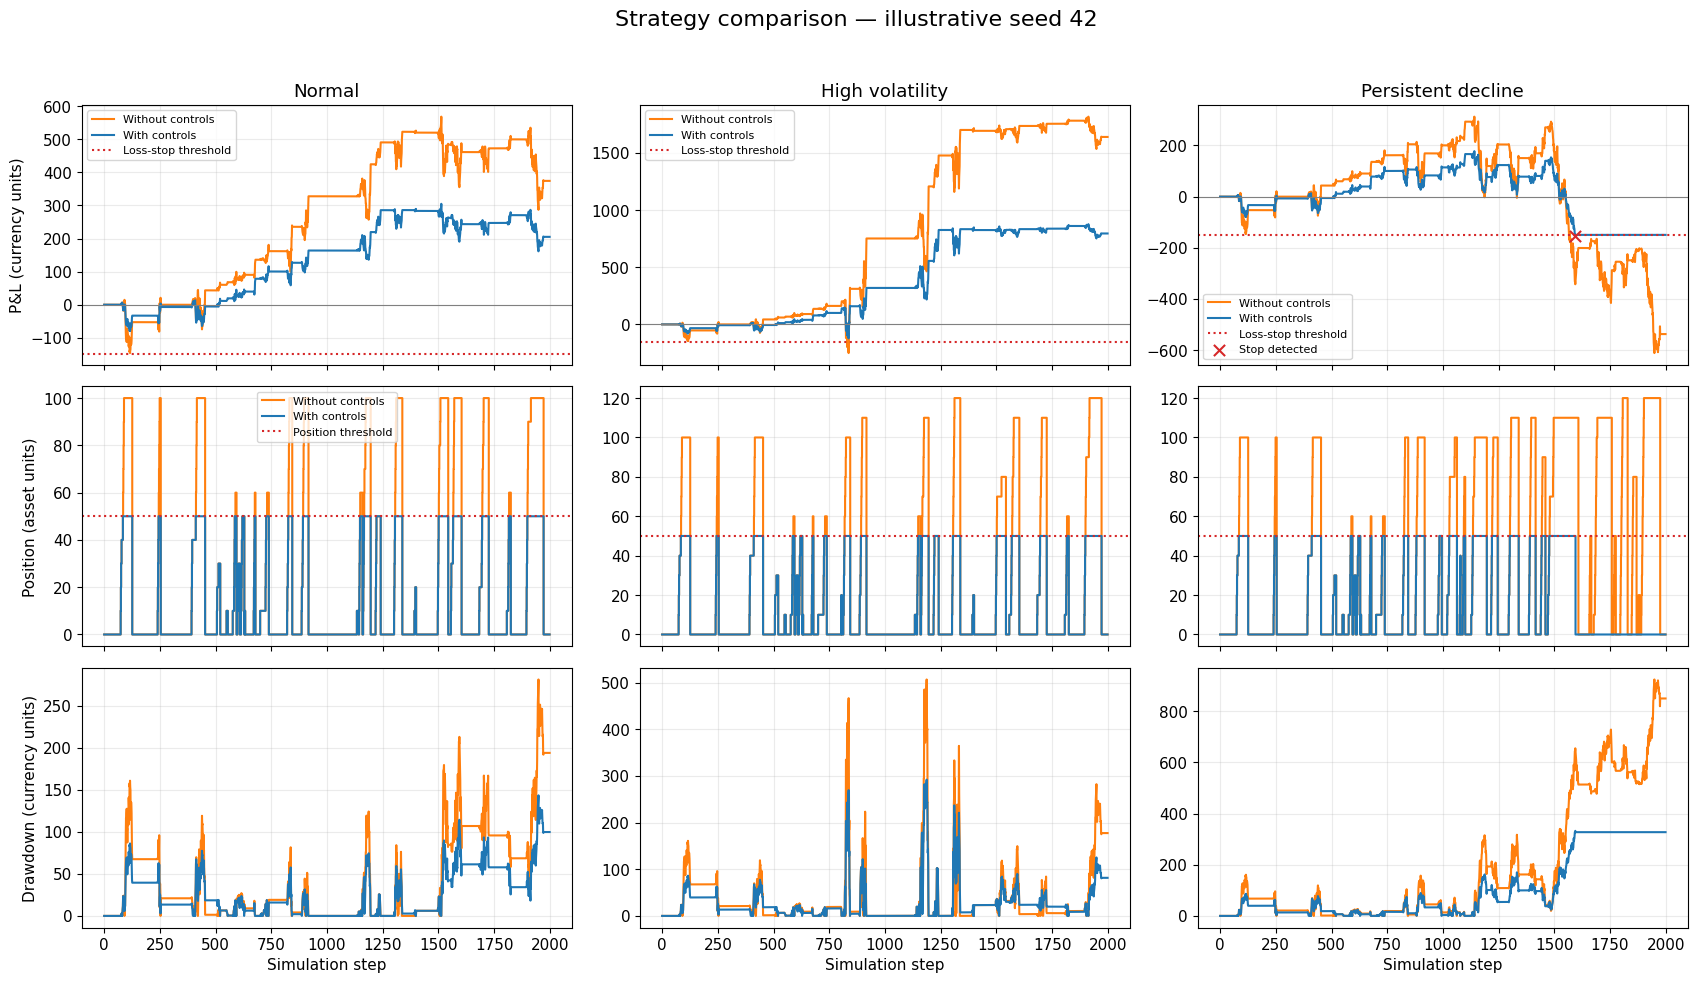

In [37]:
CONFIGURATIONS = {
    False: ("Without controls", "tab:orange"),
    True: ("With controls", "tab:blue"),
}

fig, axes = plt.subplots(
    nrows=3,
    ncols=len(SCENARIOS),
    figsize=(17, 10),
    sharex="col",
)

for column, scenario in enumerate(SCENARIOS):
    for with_controls, (label, color) in CONFIGURATIONS.items():
        history = backtests[(scenario, with_controls)]["history"]

        drawdown = (
            history["equity"].cummax() - history["equity"]
        )

        axes[0, column].plot(
            history["step"],
            history["pnl"],
            label=label,
            color=color,
        )

        axes[1, column].step(
            history["step"],
            history["position"],
            where="post",
            label=label,
            color=color,
        )

        axes[2, column].plot(
            history["step"],
            drawdown,
            label=label,
            color=color,
        )

    axes[0, column].set_title(SCENARIOS[scenario])
    axes[0, column].axhline(
        0, color="grey", linewidth=0.8
    )
    axes[0, column].axhline(
        -RISK["loss_limit"],
        color="tab:red",
        linestyle=":",
        label="Loss-stop threshold",
    )

    axes[1, column].axhline(
        RISK["max_position"],
        color="tab:red",
        linestyle=":",
        label="Position threshold",
    )

    controlled_history = backtests[(scenario, True)]["history"]
    trigger = controlled_history.loc[
        controlled_history["stop_triggered"]
    ]

    if not trigger.empty:
        axes[0, column].scatter(
            trigger["step"],
            trigger["pnl"],
            color="tab:red",
            marker="x",
            s=65,
            zorder=5,
            label="Stop detected",
        )

    axes[2, column].set_xlabel("Simulation step")

axes[0, 0].set_ylabel("P&L (currency units)")
axes[1, 0].set_ylabel("Position (asset units)")
axes[2, 0].set_ylabel("Drawdown (currency units)")

for column in range(len(SCENARIOS)):
    axes[0, column].legend(fontsize=8)

axes[1, 0].legend(fontsize=8)

fig.suptitle(
    f"Strategy comparison — illustrative seed {SEED}",
    fontsize=16,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))

fig.savefig(
    OUTPUT_DIR / "04_strategy_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [38]:
PRESENTATION_SCENARIO = "persistent_decline"

slide_metrics = {
    "Final P&L": "final_pnl",
    "Maximum drawdown": "max_drawdown",
    "Executed trades": "executed_trades",
    "Steps above position limit": "steps_above_position_limit",
}

presentation_table = pd.DataFrame(index=list(slide_metrics))
presentation_table.index.name = "Metric"

for with_controls, (label, _) in CONFIGURATIONS.items():
    metrics = summarise_backtest(
        backtests[(PRESENTATION_SCENARIO, with_controls)]
    )

    presentation_table[label] = [
        metrics[key]
        for key in slide_metrics.values()
    ]

formatted_table = presentation_table.copy()

for metric in ["Final P&L", "Maximum drawdown"]:
    formatted_table.loc[metric] = presentation_table.loc[metric].map(
        lambda value: f"{value:,.2f}"
    )

for metric in ["Executed trades", "Steps above position limit"]:
    formatted_table.loc[metric] = presentation_table.loc[metric].map(
        lambda value: f"{int(value):,}"
    )

print(
    f"Presentation scenario: {SCENARIOS[PRESENTATION_SCENARIO]}"
    f" | Seed: {SEED}"
)
display(formatted_table)

presentation_table.to_csv(
    OUTPUT_DIR / "05_presentation_table.csv"
)

Presentation scenario: Persistent decline | Seed: 42


/tmp/ipykernel_1230/3665937907.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-537.40' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  formatted_table.loc[metric] = presentation_table.loc[metric].map(
/tmp/ipykernel_1230/3665937907.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-149.54' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  formatted_table.loc[metric] = presentation_table.loc[metric].map(


,Without controls,With controls
Metric,,
Final P&L,-537.40,-149.54
Maximum drawdown,924.45,332.60
Executed trades,255,125
Steps above position limit,693,0


### Interpretation

The plots show both financial outcomes and the behaviour of the controls

The controlled configuration should never exceed its position limit.
However, a smaller position does not necessarily improve final P&L:
it can reduce both losses and gains.

The loss-stop threshold is measured relative to initial equity.
Maximum drawdown is measured relative to a previous equity peak.
These are different quantities, so maximum drawdown can exceed the
loss-stop threshold even when the stop operates correctly.

A stop also has an execution delay and liquidation costs. Its threshold
is therefore not a guaranteed upper bound on losses.

## 7. Robustness across simulation seeds

A single price path can produce an unrepresentative result.
We therefore repeat each scenario using 20 predefined random seeds

For each scenario and seed, both configurations receive the same market
path. This creates a paired comparison: differences within each pair
are caused by the controls under our execution assumptions

We keep all strategy parameters and risk thresholds fixed.
We do not select parameters based on the results of these runs

### Evaluation

We report:

- Mean and standard deviation of final P&L
- Mean maximum drawdown
- Frequency of loss-stop activation
- Paired differences in P&L and maximum drawdown

For each seed:

$$
\Delta PnL = PnL_{\text{with controls}}
             - PnL_{\text{without controls}},
$$

$$
\Delta MDD = MDD_{\text{with controls}}
             - MDD_{\text{without controls}}
$$

A positive $\Delta PnL$ favours the controlled configuration.
A negative $\Delta MDD$ indicates a smaller maximum drawdown with controls

In [39]:
repeated_rows = []

for scenario in SCENARIOS:
    for seed in SIMULATION_SEEDS:
        market_data = simulate_market(scenario, seed=seed)

        for with_controls in [False, True]:
            result = run_backtest(
                market_data,
                with_controls=with_controls,
            )

            history = result["history"]

            assert (history["cash"] >= -1e-8).all()
            assert (history["position"] >= 0).all()
            assert history["position"].iloc[-1] == 0

            assert np.allclose(
                history["equity"],
                history["cash"]
                + history["position"] * history["mid_price"],
            )

            if with_controls:
                assert (
                    history["position"] <= RISK["max_position"]
                ).all()

            repeated_rows.append({
                "scenario": scenario,
                "seed": seed,
                "with_controls": with_controls,
                **summarise_backtest(result),
            })

repeated_results = pd.DataFrame(repeated_rows)

expected_runs = (
    len(SCENARIOS) * len(SIMULATION_SEEDS) * 2
)

assert len(repeated_results) == expected_runs
assert not repeated_results.duplicated(
    ["scenario", "seed", "with_controls"]
).any()

print(f"Completed {len(repeated_results)} backtests.")
print(f"Seeds per scenario: {len(SIMULATION_SEEDS)}")

repeated_results.to_csv(
    OUTPUT_DIR / "06_repeated_simulations.csv",
    index=False,
)

Completed 120 backtests.
Seeds per scenario: 20


In [40]:
robustness_summary = (
    repeated_results
    .groupby(
        ["scenario", "with_controls"],
        sort=False,
    )
    .agg(
        runs=("seed", "count"),
        mean_pnl=("final_pnl", "mean"),
        std_pnl=("final_pnl", "std"),
        mean_max_drawdown=("max_drawdown", "mean"),
        mean_executed_trades=("executed_trades", "mean"),
        mean_steps_above_limit=(
            "steps_above_position_limit", "mean"
        ),
        stop_rate=("loss_stop_triggered", "mean"),
    )
    .reset_index()
)

summary_for_display = robustness_summary.copy()

summary_for_display["scenario"] = (
    summary_for_display["scenario"].map(SCENARIOS)
)

summary_for_display["configuration"] = (
    summary_for_display["with_controls"].map({
        False: "Without controls",
        True: "With controls",
    })
)

summary_for_display["stop_rate_pct"] = (
    100 * summary_for_display["stop_rate"]
)

display(
    summary_for_display[[
        "scenario",
        "configuration",
        "runs",
        "mean_pnl",
        "std_pnl",
        "mean_max_drawdown",
        "mean_executed_trades",
        "mean_steps_above_limit",
        "stop_rate_pct",
    ]].round(2)
)

summary_for_display.to_csv(
    OUTPUT_DIR / "07_robustness_summary.csv",
    index=False,
)

,scenario,configuration,runs,mean_pnl,std_pnl,mean_max_drawdown,mean_executed_trades,mean_steps_above_limit,stop_rate_pct
0,Normal,Without controls,20,518.370,187.300,264.290,209.300,425.100,0.000
1,Normal,With controls,20,282.600,88.490,149.960,139.150,0.000,0.000
2,High volatility,Without controls,20,"1,285.300",634.140,746.900,212.850,425.850,0.000
3,High volatility,With controls,20,297.390,546.410,378.360,103.800,0.000,55.000
4,Persistent decline,Without controls,20,-707.430,239.130,"1,094.130",242.150,770.800,0.000
5,Persistent decline,With controls,20,-158.960,14.730,313.810,103.750,0.000,100.000


In [41]:
uncontrolled = (
    repeated_results.loc[
        ~repeated_results["with_controls"]
    ]
    .set_index(["scenario", "seed"])
)

controlled = (
    repeated_results.loc[
        repeated_results["with_controls"]
    ]
    .set_index(["scenario", "seed"])
)

assert controlled.index.equals(uncontrolled.index)

paired_results = pd.DataFrame({
    "pnl_difference": (
        controlled["final_pnl"]
        - uncontrolled["final_pnl"]
    ),
    "drawdown_difference": (
        controlled["max_drawdown"]
        - uncontrolled["max_drawdown"]
    ),
}).reset_index()

tolerance = 1e-8

paired_results["higher_pnl_with_controls"] = (
    paired_results["pnl_difference"] > tolerance
)
paired_results["lower_drawdown_with_controls"] = (
    paired_results["drawdown_difference"] < -tolerance
)

paired_summary = (
    paired_results
    .groupby("scenario", sort=False)
    .agg(
        pairs=("seed", "count"),
        mean_pnl_difference=("pnl_difference", "mean"),
        mean_drawdown_difference=("drawdown_difference", "mean"),
        higher_pnl_pairs=("higher_pnl_with_controls", "sum"),
        lower_drawdown_pairs=("lower_drawdown_with_controls", "sum"),
    )
    .reset_index()
)

paired_summary["scenario"] = (
    paired_summary["scenario"].map(SCENARIOS)
)

display(paired_summary.round(2))

paired_results.to_csv(
    OUTPUT_DIR / "08_paired_results.csv",
    index=False,
)

,scenario,pairs,mean_pnl_difference,mean_drawdown_difference,higher_pnl_pairs,lower_drawdown_pairs
0,Normal,20,-235.760,-114.330,0,20
1,High volatility,20,-987.920,-368.530,0,20
2,Persistent decline,20,548.470,-780.320,20,20


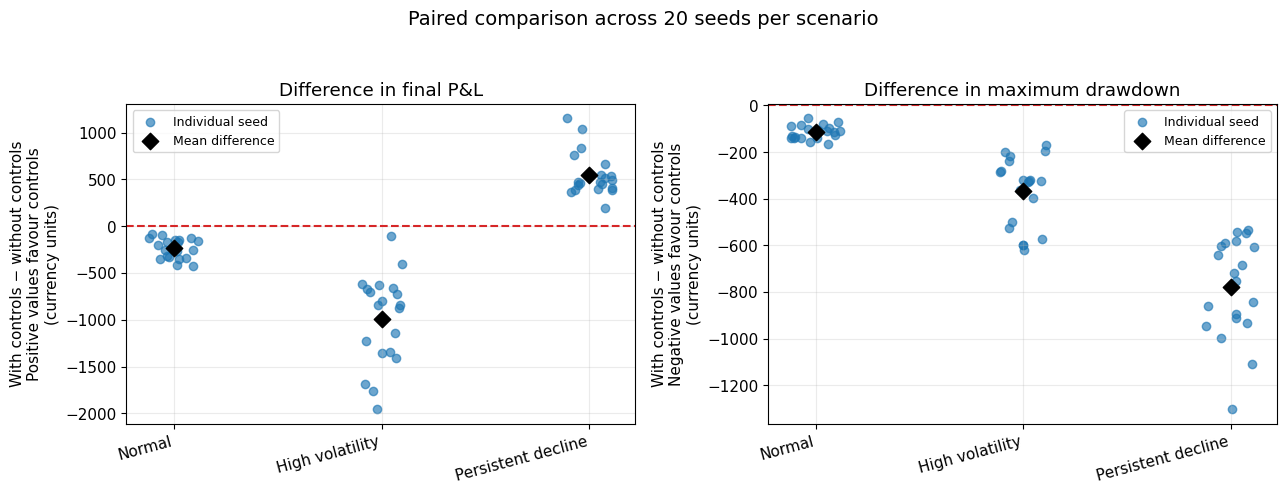

In [42]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5),
)

plot_settings = [
    (
        "pnl_difference",
        "Difference in final P&L",
        "With controls − without controls\n"
        "Positive values favour controls",
    ),
    (
        "drawdown_difference",
        "Difference in maximum drawdown",
        "With controls − without controls\n"
        "Negative values favour controls",
    ),
]

scenario_names = list(SCENARIOS)
jitter_rng = np.random.default_rng(SEED + 1_000)

for ax, (metric, title, ylabel) in zip(axes, plot_settings):
    for position, scenario in enumerate(scenario_names):
        values = paired_results.loc[
            paired_results["scenario"].eq(scenario),
            metric,
        ].to_numpy()

        jitter = jitter_rng.uniform(
            -0.12, 0.12, size=len(values)
        )

        ax.scatter(
            position + jitter,
            values,
            alpha=0.65,
            color="tab:blue",
            label="Individual seed" if position == 0 else None,
        )

        ax.scatter(
            position,
            values.mean(),
            marker="D",
            s=70,
            color="black",
            zorder=5,
            label="Mean difference" if position == 0 else None,
        )

    ax.axhline(0, color="tab:red", linestyle="--")
    ax.set_xticks(range(len(scenario_names)))
    ax.set_xticklabels(
        [SCENARIOS[name] for name in scenario_names],
        rotation=15,
        ha="right",
    )
    ax.set_title(title)
    ax.set_ylabel(f"{ylabel}\n(currency units)")
    ax.legend(fontsize=9)

fig.suptitle(
    "Paired comparison across 20 seeds per scenario",
    fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))

fig.savefig(
    OUTPUT_DIR / "09_paired_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### How to interpret the results

Each blue point represents one paired comparison on an identical market
path. Black diamonds show mean differences across the 20 seeds

The P&L plot shows whether controls improved or reduced the final financial
result. The drawdown plot shows whether they reduced peak-to-trough losses

If differences cross zero, the effect varies across simulated paths.
An average improvement does not imply an improvement in every run

The controlled configuration combines a position limit and a loss-triggered
stop. This experiment estimates their combined effect; it does not isolate
the contribution of each control

## 8. Synthetic trading activity for anomaly detection

The paper discusses anomaly detection as a possible application of AI
in trading-system testing. We illustrate this idea using a separate
synthetic monitoring dataset

Each observation represents one monitoring window of equal duration.
We generate window-level features directly, rather than reconstructing
them from individual order messages

This dataset is independent of the strategy backtests. The anomaly
detector does not affect the trading decisions in Experiment A

### Features

| Feature | Description |
|---|---|
| order_count | Number of submitted orders in the window |
| cancellation_ratio | Fraction of those orders cancelled within the window |
| mean_order_size | Average submitted order size, in asset units |
| mean_latency_ms | Average simulated order-processing latency, in milliseconds |

Normal observations have varying activity levels. We also introduce a
weak relationship between activity and latency: busier windows tend to
have slightly higher processing latency

### Injected anomaly types

1. **Order burst:** unusually high order count
2. **High cancellation:** unusually high cancellation probability
3. **Latency spike:** unusually high processing latency

These are synthetic deviations from the chosen normal data-generating
process. They do not establish spoofing, manipulation or a legal violation.
For example, legitimate activity can also produce high cancellation rates

### Data separation

- **Training:** 3,000 normal windows, used to fit the detectors
- **Calibration:** 2,000 independent normal windows, used to set thresholds
- **Test:** 2,000 independent windows, including 6% injected anomalies

Labels and anomaly types are simulator metadata. They are excluded from
model inputs. Test labels will be used only for evaluation, not to choose
model parameters or alert thresholds

In [43]:
FEATURE_COLUMNS = [
    "order_count",
    "cancellation_ratio",
    "mean_order_size",
    "mean_latency_ms",
]


def generate_activity(n_windows, seed, anomaly_fraction=0.0):
    if n_windows < 1:
        raise ValueError("n_windows must be positive")

    if not 0 <= anomaly_fraction <= 1:
        raise ValueError("anomaly_fraction must be between 0 and 1")

    rng = np.random.default_rng(seed)

    intensity = rng.lognormal(
        mean=np.log(80),
        sigma=0.35,
        size=n_windows,
    )
    order_count = np.maximum(
        rng.poisson(intensity),
        1,
    )

    cancellation_probability = rng.beta(
        a=4,
        b=8,
        size=n_windows,
    )

    mean_order_size = rng.lognormal(
        mean=np.log(10),
        sigma=0.40,
        size=n_windows,
    )

    mean_latency_ms = rng.lognormal(
        mean=np.log(2.5) + 0.15 * np.log(order_count / 80),
        sigma=0.25,
        size=n_windows,
    )

    anomaly_type = np.full(
        n_windows,
        "normal",
        dtype=object,
    )

    n_anomalies = int(round(n_windows * anomaly_fraction))

    if n_anomalies > 0:
        anomaly_indices = rng.choice(
            n_windows,
            size=n_anomalies,
            replace=False,
        )

        injected_types = np.resize(
            np.array([
                "order_burst",
                "high_cancellation",
                "latency_spike",
            ]),
            n_anomalies,
        )
        rng.shuffle(injected_types)
        anomaly_type[anomaly_indices] = injected_types

        burst_mask = anomaly_type == "order_burst"
        order_count[burst_mask] = np.rint(
            order_count[burst_mask]
            * rng.uniform(3.0, 6.0, size=burst_mask.sum())
        ).astype(int)

        cancellation_mask = anomaly_type == "high_cancellation"
        cancellation_probability[cancellation_mask] = rng.uniform(
            0.85,
            0.98,
            size=cancellation_mask.sum(),
        )

        latency_mask = anomaly_type == "latency_spike"
        mean_latency_ms[latency_mask] *= rng.uniform(
            3.0,
            6.0,
            size=latency_mask.sum(),
        )

    cancelled_orders = rng.binomial(
        n=order_count,
        p=cancellation_probability,
    )
    cancellation_ratio = cancelled_orders / order_count

    return pd.DataFrame({
        "order_count": order_count,
        "cancellation_ratio": cancellation_ratio,
        "mean_order_size": mean_order_size,
        "mean_latency_ms": mean_latency_ms,
        "is_anomaly": (anomaly_type != "normal").astype(int),
        "anomaly_type": anomaly_type,
    })

In [44]:
activity_train = generate_activity(
    n_windows=DETECTION["n_train"],
    seed=SEED + 200,
)

activity_calibration = generate_activity(
    n_windows=DETECTION["n_calibration"],
    seed=SEED + 201,
)

activity_test = generate_activity(
    n_windows=DETECTION["n_test"],
    seed=SEED + 202,
    anomaly_fraction=DETECTION["test_anomaly_fraction"],
)

X_train = activity_train[FEATURE_COLUMNS].copy()
X_calibration = activity_calibration[FEATURE_COLUMNS].copy()
X_test = activity_test[FEATURE_COLUMNS].copy()

y_test = activity_test["is_anomaly"].copy()

for dataset in [
    activity_train,
    activity_calibration,
    activity_test,
]:
    assert np.isfinite(
        dataset[FEATURE_COLUMNS].to_numpy()
    ).all()

    assert (dataset["order_count"] >= 1).all()
    assert dataset["cancellation_ratio"].between(0, 1).all()
    assert (dataset["mean_order_size"] > 0).all()
    assert (dataset["mean_latency_ms"] > 0).all()

assert activity_train["is_anomaly"].sum() == 0
assert activity_calibration["is_anomaly"].sum() == 0

assert y_test.sum() == round(
    DETECTION["n_test"]
    * DETECTION["test_anomaly_fraction"]
)

assert "is_anomaly" not in X_train.columns
assert "anomaly_type" not in X_train.columns

dataset_summary = pd.DataFrame([
    {
        "dataset": name,
        "windows": len(data),
        "normal": int(data["is_anomaly"].eq(0).sum()),
        "injected_anomalies": int(data["is_anomaly"].sum()),
    }
    for name, data in [
        ("Training", activity_train),
        ("Calibration", activity_calibration),
        ("Test", activity_test),
    ]
])

display(dataset_summary)

print("\nTraining feature distributions:")
display(X_train.describe().round(3))

print("\nInjected test labels — reserved for evaluation:")
display(
    activity_test["anomaly_type"]
    .value_counts()
    .rename_axis("Type")
    .to_frame("Windows")
)

,dataset,windows,normal,injected_anomalies
0,Training,3000,3000,0
1,Calibration,2000,2000,0
2,Test,2000,1880,120



Training feature distributions:


,order_count,cancellation_ratio,mean_order_size,mean_latency_ms
count,"3,000.000","3,000.000","3,000.000","3,000.000"
mean,84.485,0.334,10.762,2.582
std,31.534,0.142,4.459,0.671
min,16.000,0.012,2.622,0.961
25%,62.000,0.229,7.648,2.099
50%,80.000,0.324,9.900,2.497
75%,102.000,0.431,12.940,2.975
max,245.000,0.838,37.818,5.552



Injected test labels — reserved for evaluation:


,Windows
Type,
normal,1880
latency_spike,40
order_burst,40
high_cancellation,40


### Interpretation and limitations

The training and calibration samples contain normal activity only.
The detector must identify deviations in previously unseen test windows
without learning from labelled anomaly examples

The test anomaly fraction is a simulation choice, not an estimate of
real-world prevalence. Precision will depend on this fraction

The labels indicate which windows were modified by the generator.
Because normal and injected distributions can overlap, detection need
not be perfect

This experiment assumes independent windows and a stable normal
distribution. Real monitoring data can exhibit temporal dependence,
changing activity regimes and contaminated training samples

## 9. Detector training and threshold calibration

We compare two methods using the same four features and the same
training and calibration samples

### Feature transformation

Order count, mean order size and mean latency are positive and right-skewed.
We apply a natural logarithm to these three features.
The cancellation ratio remains unchanged

This transformation is specified before evaluation and applied identically
to training, calibration and test observations

### Baseline: maximum absolute standardised deviation

For each transformed feature, we estimate its mean and sample standard
deviation from the training sample

The baseline score is:

$$
S_{\text{baseline}}(x)
=
\max_j
\left|
\frac{x_j-\widehat{\mu}_j}{\widehat{\sigma}_j}
\right|
$$

A large score means that at least one feature is far from its training mean.
This is an interpretable threshold baseline, not a probability estimate

### Isolation Forest

Isolation Forest uses random feature splits to isolate observations.
Observations isolated with shorter paths tend to receive more anomalous
scores.

We fit the model on normal training windows only. We negate scikit-learn's
score_samples output so that larger scores indicate greater abnormality

### Threshold calibration

For each detector, we select the empirical 99th percentile of its scores
on the independent normal calibration sample

An alert is generated when the score strictly exceeds that threshold.

Both methods therefore target approximately 1% false alerts on normal
calibration data

Method reference:
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html

In [45]:
LOG_FEATURES = [
    "order_count",
    "mean_order_size",
    "mean_latency_ms",
]


def transform_activity_features(features):
    transformed = features[FEATURE_COLUMNS].astype(float).copy()

    if (transformed[LOG_FEATURES] <= 0).any().any():
        raise ValueError("Log-transformed features must be positive")

    transformed[LOG_FEATURES] = np.log(
        transformed[LOG_FEATURES]
    )

    return transformed


X_train_transformed = transform_activity_features(X_train)
X_calibration_transformed = transform_activity_features(X_calibration)

baseline_mean = X_train_transformed.mean()
baseline_std = X_train_transformed.std(ddof=1)

if (baseline_std <= 0).any():
    raise ValueError("Baseline features must have non-zero variance")


def baseline_anomaly_score(transformed_features):
    standardised = (
        transformed_features - baseline_mean
    ) / baseline_std

    return standardised.abs().max(axis=1).to_numpy()


print("Feature transformation and baseline fitting complete")

Feature transformation and baseline fitting complete


In [46]:
isolation_forest = IsolationForest(
    n_estimators=DETECTION["n_estimators"],
    max_samples=256,
    contamination="auto",
    random_state=SEED,
    n_jobs=1,
)

isolation_forest.fit(X_train_transformed)


def isolation_anomaly_score(transformed_features):
    return -isolation_forest.score_samples(transformed_features)


print("Isolation Forest training complete")
print(f"Training windows: {len(X_train_transformed):,}")
print(f"Number of trees: {DETECTION['n_estimators']}")

Isolation Forest training complete
Training windows: 3,000
Number of trees: 200


In [47]:
alpha = DETECTION["target_false_positive_rate"]

if not 0 < alpha < 1:
    raise ValueError("The target false-positive rate must be between 0 and 1")

calibration_scores = {
    "Threshold baseline": baseline_anomaly_score(
        X_calibration_transformed
    ),
    "Isolation Forest": isolation_anomaly_score(
        X_calibration_transformed
    ),
}

thresholds = {}
calibration_rows = []

for detector_name, scores in calibration_scores.items():
    assert np.isfinite(scores).all()

    threshold = float(
        np.quantile(scores, 1 - alpha, method="higher")
    )

    thresholds[detector_name] = threshold
    alerts = scores > threshold

    calibration_rows.append({
        "detector": detector_name,
        "threshold": threshold,
        "normal_windows": len(scores),
        "false_alerts": int(alerts.sum()),
        "calibration_fpr_pct": 100 * alerts.mean(),
        "target_fpr_pct": 100 * alpha,
    })

calibration_summary = pd.DataFrame(calibration_rows)

display(calibration_summary.round(4))

calibration_summary.to_csv(
    OUTPUT_DIR / "10_detector_calibration.csv",
    index=False,
)

,detector,threshold,normal_windows,false_alerts,calibration_fpr_pct,target_fpr_pct
0,Threshold baseline,2.920,2000,19,0.950,1.000
1,Isolation Forest,0.593,2000,19,0.950,1.000


### Interpretation

Every calibration observation is normal by construction, so every alert
on this sample is a false alert

The calibration table checks that both detectors operate near the same
predefined false-alert target. It does not measure their ability to
detect anomalies

Score scales differ between methods. A larger numerical threshold does
not indicate a better detector

## 10. Held-out evaluation of anomaly detection

We apply the fitted detectors and fixed calibration thresholds to the
held-out test sample

An injected anomaly is the positive class:

- **True positive (TP):** an injected anomaly correctly flagged
- **False positive (FP):** a normal window incorrectly flagged
- **False negative (FN):** an injected anomaly missed
- **True negative (TN):** a normal window correctly left unflagged

### Evaluation metrics

$$
Precision = \frac{TP}{TP+FP},
\qquad
Recall = \frac{TP}{TP+FN},
$$

$$
F_1 = \frac{2 \cdot Precision \cdot Recall}{Precision+Recall},
\qquad
FPR = \frac{FP}{FP+TN}
$$

Precision measures the fraction of alerts that correspond to injected
anomalies. Recall measures the fraction of injected anomalies detected.
FPR measures the fraction of normal windows incorrectly flagged

We also report average precision (AP), which summarises the precision–recall
ranking across score thresholds. AP uses continuous anomaly scores rather
than the fixed alert decisions

Finally, we measure recall separately for each injected anomaly type

In [48]:
X_test_transformed = transform_activity_features(X_test)

test_scores = {
    "Threshold baseline": baseline_anomaly_score(
        X_test_transformed
    ),
    "Isolation Forest": isolation_anomaly_score(
        X_test_transformed
    ),
}

test_predictions = {}
confusion_matrices = {}
evaluation_rows = []

for detector_name, scores in test_scores.items():
    assert np.isfinite(scores).all()

    predictions = (
        scores > thresholds[detector_name]
    ).astype(int)

    test_predictions[detector_name] = predictions

    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1],
    )
    confusion_matrices[detector_name] = matrix

    tn, fp, fn, tp = matrix.ravel()

    evaluation_rows.append({
        "detector": detector_name,
        "true_positives": int(tp),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_negatives": int(tn),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "test_fpr": fp / (fp + tn),
        "average_precision": average_precision_score(
            y_test, scores
        ),
    })

detection_results = pd.DataFrame(evaluation_rows)

evaluation_display = detection_results[[
    "detector",
    "true_positives",
    "false_positives",
    "false_negatives",
    "true_negatives",
]].copy()

for metric in ["precision", "recall", "f1", "test_fpr"]:
    evaluation_display[f"{metric}_pct"] = (
        100 * detection_results[metric]
    )

evaluation_display["average_precision"] = (
    detection_results["average_precision"]
)

display(evaluation_display.round(2))

detection_results.to_csv(
    OUTPUT_DIR / "11_anomaly_detection_metrics.csv",
    index=False,
)

,detector,true_positives,false_positives,false_negatives,true_negatives,precision_pct,recall_pct,f1_pct,test_fpr_pct,average_precision
0,Threshold baseline,116,29,4,1851,80.000,96.670,87.550,1.540,0.970
1,Isolation Forest,27,23,93,1857,54.000,22.500,31.760,1.220,0.520


In [49]:
anomaly_types = [
    "order_burst",
    "high_cancellation",
    "latency_spike",
]

type_rows = []

for detector_name, predictions in test_predictions.items():
    for anomaly_type in anomaly_types:
        mask = (
            activity_test["anomaly_type"]
            .eq(anomaly_type)
            .to_numpy()
        )

        total = int(mask.sum())
        detected = int(predictions[mask].sum())

        type_rows.append({
            "detector": detector_name,
            "anomaly_type": anomaly_type,
            "total_anomalies": total,
            "detected": detected,
            "missed": total - detected,
            "recall_pct": 100 * detected / total,
        })

type_results = pd.DataFrame(type_rows)

display(type_results.round(2))

for detector_name in test_predictions:
    type_detected = type_results.loc[
        type_results["detector"].eq(detector_name),
        "detected",
    ].sum()

    overall_detected = detection_results.loc[
        detection_results["detector"].eq(detector_name),
        "true_positives",
    ].iloc[0]

    assert type_detected == overall_detected

type_results.to_csv(
    OUTPUT_DIR / "12_detection_by_anomaly_type.csv",
    index=False,
)

,detector,anomaly_type,total_anomalies,detected,missed,recall_pct
0,Threshold baseline,order_burst,40,36,4,90.000
1,Threshold baseline,high_cancellation,40,40,0,100.000
2,Threshold baseline,latency_spike,40,40,0,100.000
3,Isolation Forest,order_burst,40,5,35,12.500
4,Isolation Forest,high_cancellation,40,13,27,32.500
5,Isolation Forest,latency_spike,40,9,31,22.500


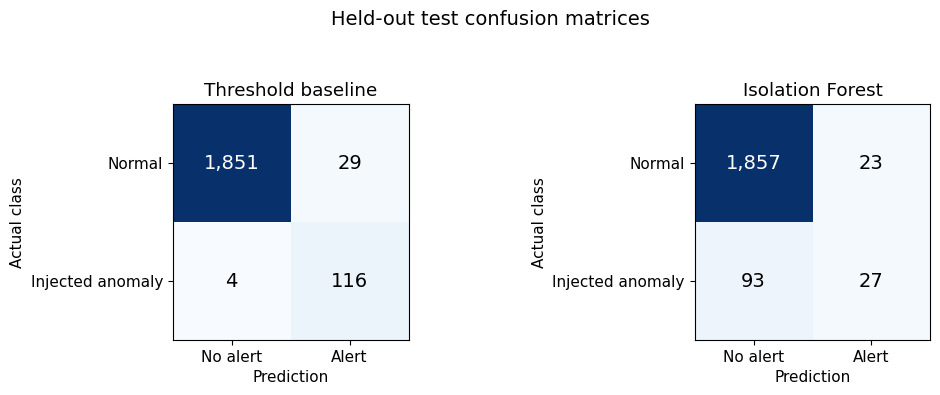

In [50]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 4),
)

largest_count = max(
    matrix.max()
    for matrix in confusion_matrices.values()
)

for ax, (detector_name, matrix) in zip(
    axes, confusion_matrices.items()
):
    ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=largest_count,
    )

    for row in range(2):
        for column in range(2):
            value = matrix[row, column]
            ax.text(
                column,
                row,
                f"{value:,}",
                ha="center",
                va="center",
                fontsize=14,
                color=(
                    "white"
                    if value > largest_count / 2
                    else "black"
                ),
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["No alert", "Alert"])
    ax.set_yticklabels(["Normal", "Injected anomaly"])
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual class")
    ax.set_title(detector_name)
    ax.grid(False)

fig.suptitle("Held-out test confusion matrices", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.93))

fig.savefig(
    OUTPUT_DIR / "13_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

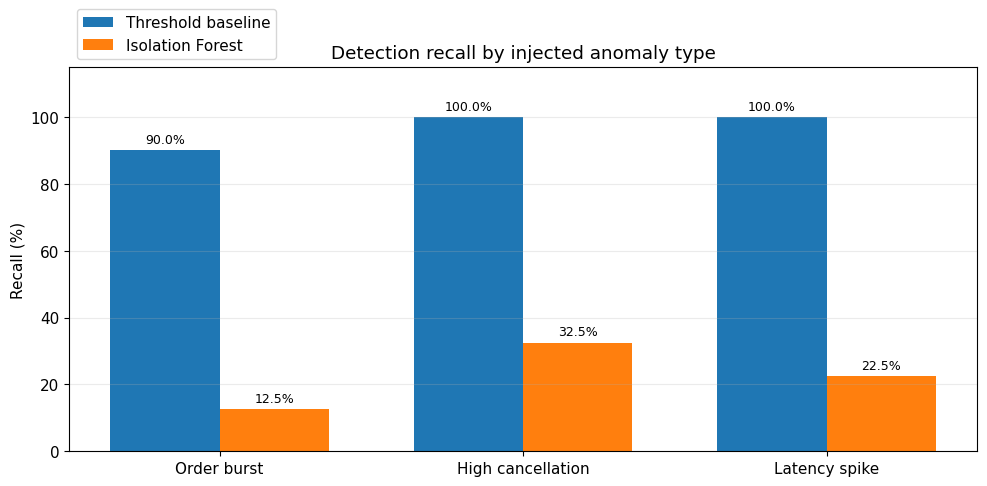

In [51]:
type_labels = {
    "order_burst": "Order burst",
    "high_cancellation": "High cancellation",
    "latency_spike": "Latency spike",
}

x = np.arange(len(anomaly_types))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

for index, detector_name in enumerate(test_predictions):
    values = (
        type_results.loc[
            type_results["detector"].eq(detector_name)
        ]
        .set_index("anomaly_type")
        .loc[anomaly_types, "recall_pct"]
        .to_numpy()
    )

    offset = (index - 0.5) * bar_width

    bars = ax.bar(
        x + offset,
        values,
        width=bar_width,
        label=detector_name,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in values],
        padding=3,
        fontsize=9,
    )

ax.set_xticks(x)
ax.set_xticklabels([
    type_labels[name] for name in anomaly_types
])
ax.set_ylim(0, 115)
ax.set_ylabel("Recall (%)")
ax.set_title("Detection recall by injected anomaly type")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.17))
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "14_recall_by_anomaly_type.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Interpretation

A useful detector must balance anomaly detection against false alerts.
High recall alone is insufficient if many normal windows are also flagged

The type-level results identify which injected patterns each method
detects or misses. With only 40 examples per type, one additional detection
changes recall by 2.5 percentage points

Isolation Forest is not assumed to outperform the threshold baseline.
The injected anomalies mainly increase individual feature values, which
can favour a simple threshold method. This dataset provides a limited
comparison, not a general benchmark of anomaly detection algorithms

Average precision evaluates score ranking; precision, recall and F1
evaluate decisions at the fixed calibrated threshold. These answer
different questions

## 11. Conclusions

### Experiment A: trading strategy and risk controls

We implemented a long-only mean-reversion strategy and evaluated it
under normal conditions, increased volatility and a persistent decline

Both configurations used identical prices and execution assumptions,
including spread, fees and a one-step signal-to-execution delay

In the illustrative persistent-decline scenario with seed 42:

| Metric | Without controls | With controls |
|---|---:|---:|
| Final P&L | −537.40 | −149.54 |
| Maximum drawdown | 924.45 | 332.60 |
| Executed trades | 255 | 125 |
| Steps above the 50-unit position threshold | 693 | 0 |

Monetary values are in synthetic currency units

In this example, the combined controls reduced the final loss and
maximum drawdown while preventing positions above 50 units

Across the 20 simulated seeds per scenario, drawdown reduction was
more consistent than P&L improvement. The effect on final P&L depended
on the price path. Limiting exposure can reduce both losses and gains

The position limit and loss-triggered stop were evaluated together.
Their individual contributions were not isolated

### Experiment B: anomaly detection

We compared an interpretable threshold baseline with Isolation Forest.
Both methods used the same features and were calibrated independently
to approximately 1% false alerts on a separate normal sample

On the held-out test sample:

| Metric | Threshold baseline | Isolation Forest |
|---|---:|---:|
| Detected anomalies out of 120 | 116 | 27 |
| False alerts among 1,880 normal windows | 29 | 23 |
| Precision | 80.00% | 54.00% |
| Recall | 96.67% | 22.50% |
| F1 | 87.55% | 31.76% |
| Test false-positive rate | 1.54% | 1.22% |

The threshold baseline detected substantially more injected anomalies,
while Isolation Forest generated slightly fewer false alerts

The injected anomalies mainly increased individual feature values.
This construction is well suited to the baseline's maximum-deviation
rule. The result demonstrates the importance of comparing ML methods
with simple alternatives; it does not establish that threshold methods
are generally superior

### Connection to the paper

The paper proposes combining trading-strategy testing with applicable
requirements and discusses potential uses of AI

Our implementation illustrates two selected components:

1. Scenario-based evaluation of strategy behaviour and internal controls
2. Detection of unusual activity using a fitted ML model and a baseline

Market scenarios were specified manually. We did not implement AI-based
scenario generation, regulatory-text interpretation or dynamic selection
of country-specific requirements

### Main limitations

- Market and monitoring data are synthetic and not empirically calibrated
- Execution assumes sufficient liquidity and omits market impact,
  partial fills and additional slippage
- Trading results depend on one market model and one strategy specification
- Monitoring windows are independent and normal behaviour is stationary
- Anomaly detection uses one training/calibration/test generation and one
  Isolation Forest seed; its variability across repetitions is not assessed
- Test anomalies represent only three predefined types
- Internal risk thresholds do not implement specific legal requirements

### Overall conclusion

Scenario testing helps reveal how trading strategies and controls behave
under predefined conditions. In our simulations, controls reduced
drawdown more consistently than they improved P&L

For the selected synthetic anomalies, a simple threshold baseline
outperformed Isolation Forest on detection metrics